In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import ultralytics
import ipykernel

print("Setup successful!")
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("scikit-image version:", skimage.__version__)
print("Ultralytics version:", ultralytics.__version__)

Matplotlib is building the font cache; this may take a moment.


Setup successful!
OpenCV version: 5.0.0
NumPy version: 2.5.4
scikit-image version: 0.26.0
Ultralytics version: 8.4.182


Image loaded successfully!
Image dimensions (height, width, channels): (8192, 4608, 3)
Image data type: uint8


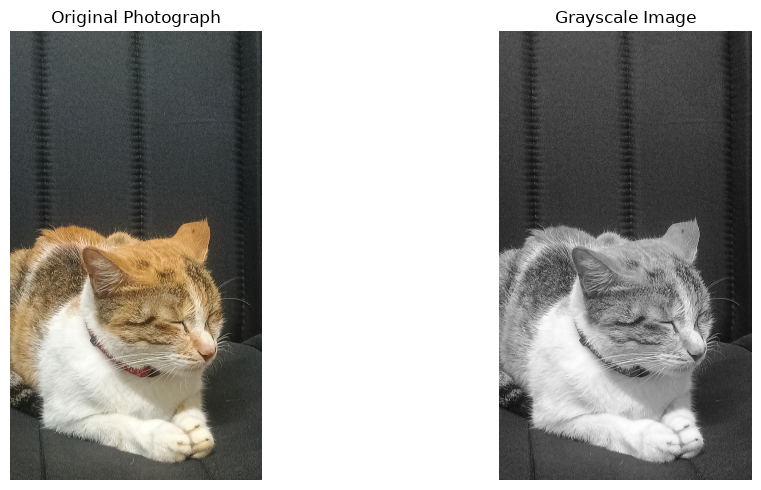

Saved: D:\Computer Vision Project\outputs\grayscale.png


In [2]:

from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Project location
PROJECT_DIR = Path(r"D:\Computer Vision Project")
INPUT_DIR = PROJECT_DIR / "input"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Create the output folder if it doesn't exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Read your photograph
image_path = INPUT_DIR / "original.jpg"
image_bgr = cv2.imread(str(image_path))

if image_bgr is None:
    raise FileNotFoundError(
        f"Image not found or unreadable: {image_path}\n"
        "Check the filename and extension in the input folder."
    )

# OpenCV reads BGR; Matplotlib displays RGB
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

print("Image loaded successfully!")
print("Image dimensions (height, width, channels):", image_bgr.shape)
print("Image data type:", image_bgr.dtype)

# Display the original and grayscale versions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Photograph")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Save the grayscale image
cv2.imwrite(str(OUTPUT_DIR / "grayscale.png"), gray)
print("Saved:", OUTPUT_DIR / "grayscale.png")


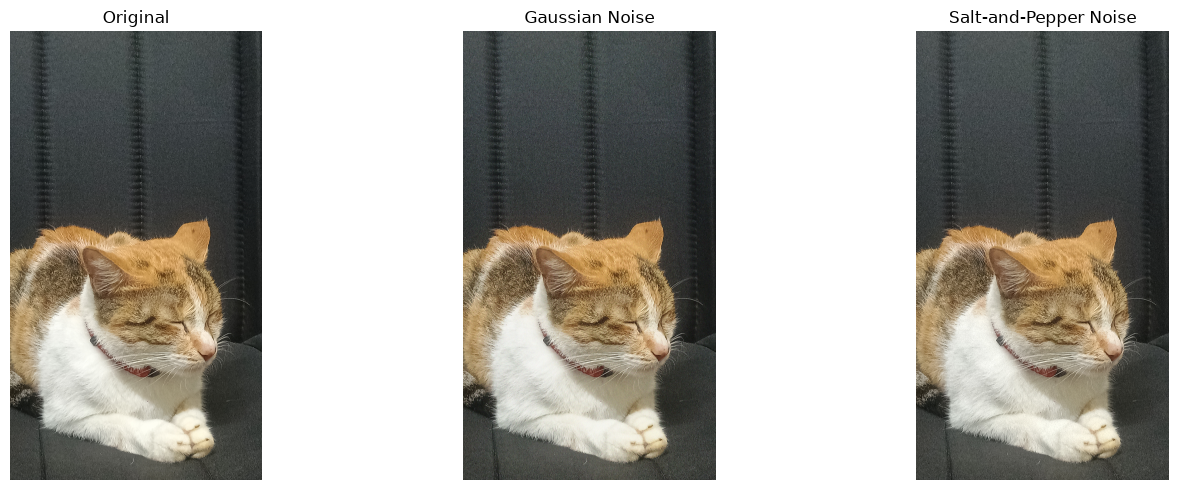

Both noisy images saved successfully.


In [3]:

# Experiment 1: Add Gaussian and salt-and-pepper noise

# Use a fixed seed so results are reproducible
rng = np.random.default_rng(42)

# Gaussian noise
gaussian_noise = rng.normal(
    loc=0,
    scale=25,
    size=image_bgr.shape
)

noisy_gaussian = np.clip(
    image_bgr.astype(np.float32) + gaussian_noise,
    0,
    255
).astype(np.uint8)

# Salt-and-pepper noise
noisy_sp = image_bgr.copy()
height, width = gray.shape

noise_mask = rng.random((height, width))
salt_mask = noise_mask > 0.98
pepper_mask = noise_mask < 0.02

noisy_sp[salt_mask] = [255, 255, 255]
noisy_sp[pepper_mask] = [0, 0, 0]

# Convert to RGB for correct display
gaussian_rgb = cv2.cvtColor(
    noisy_gaussian, cv2.COLOR_BGR2RGB
)
sp_rgb = cv2.cvtColor(
    noisy_sp, cv2.COLOR_BGR2RGB
)

# Display the comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")
axes[1].imshow(gaussian_rgb)
axes[1].set_title("Gaussian Noise")
axes[2].imshow(sp_rgb)
axes[2].set_title("Salt-and-Pepper Noise")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save both noisy images
cv2.imwrite(
    str(OUTPUT_DIR / "gaussian_noise.png"),
    noisy_gaussian
)
cv2.imwrite(
    str(OUTPUT_DIR / "salt_pepper_noise.png"),
    noisy_sp
)

print("Both noisy images saved successfully.")


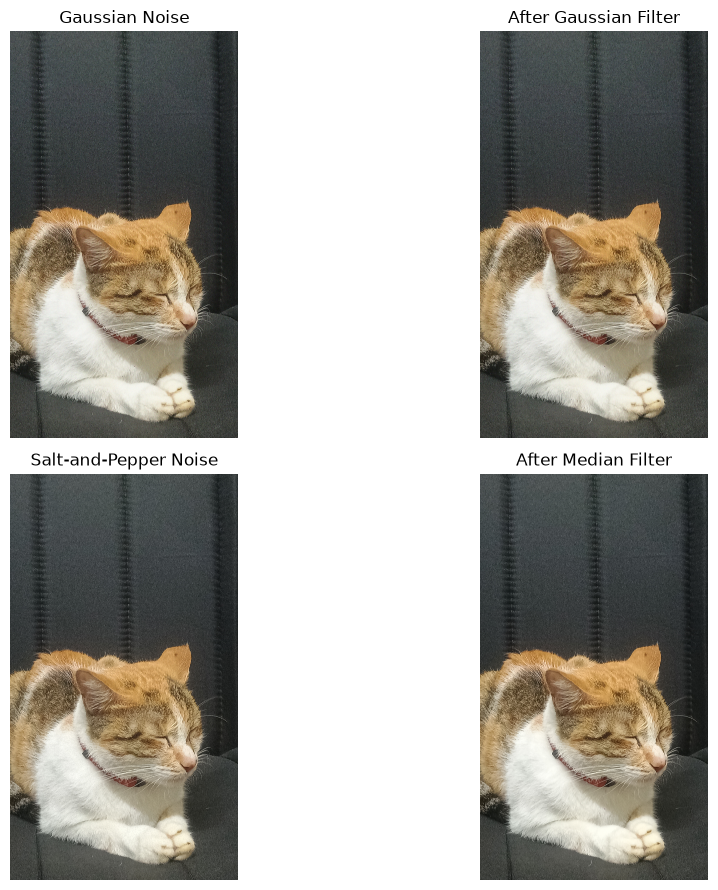

Filtered images saved successfully.


In [4]:

# Gaussian filtering and median filtering

# Gaussian filter: smooths noise using a weighted average
gaussian_filtered = cv2.GaussianBlur(
    noisy_gaussian,
    (5, 5),
    0
)

# Median filter: effective for salt-and-pepper noise
median_filtered = cv2.medianBlur(
    noisy_sp,
    5
)

# Convert BGR to RGB for display
gaussian_filtered_rgb = cv2.cvtColor(
    gaussian_filtered,
    cv2.COLOR_BGR2RGB
)

median_filtered_rgb = cv2.cvtColor(
    median_filtered,
    cv2.COLOR_BGR2RGB
)

# Display results
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].imshow(gaussian_rgb)
axes[0, 0].set_title("Gaussian Noise")

axes[0, 1].imshow(gaussian_filtered_rgb)
axes[0, 1].set_title("After Gaussian Filter")

axes[1, 0].imshow(sp_rgb)
axes[1, 0].set_title("Salt-and-Pepper Noise")

axes[1, 1].imshow(median_filtered_rgb)
axes[1, 1].set_title("After Median Filter")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save restored images
cv2.imwrite(
    str(OUTPUT_DIR / "gaussian_filtered.png"),
    gaussian_filtered
)

cv2.imwrite(
    str(OUTPUT_DIR / "median_filtered.png"),
    median_filtered
)

print("Filtered images saved successfully.")


In [5]:

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Convert images to RGB for consistent comparisons
original_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

gaussian_noisy_rgb = cv2.cvtColor(
    noisy_gaussian, cv2.COLOR_BGR2RGB
)

gaussian_restored_rgb = cv2.cvtColor(
    gaussian_filtered, cv2.COLOR_BGR2RGB
)

sp_noisy_rgb = cv2.cvtColor(
    noisy_sp, cv2.COLOR_BGR2RGB
)

median_restored_rgb = cv2.cvtColor(
    median_filtered, cv2.COLOR_BGR2RGB
)

def evaluate_image(reference, result, label):
    psnr = peak_signal_noise_ratio(
        reference, result, data_range=255
    )
    ssim = structural_similarity(
        reference,
        result,
        channel_axis=-1,
        data_range=255
    )

    print(f"{label}")
    print(f"  PSNR: {psnr:.2f} dB")
    print(f"  SSIM: {ssim:.4f}")
    return psnr, ssim

results = {}

results["Gaussian noisy"] = evaluate_image(
    original_rgb, gaussian_noisy_rgb, "Gaussian noisy"
)

results["Gaussian filtered"] = evaluate_image(
    original_rgb, gaussian_restored_rgb, "Gaussian filtered"
)

results["Salt-pepper noisy"] = evaluate_image(
    original_rgb, sp_noisy_rgb, "Salt-and-pepper noisy"
)

results["Median filtered"] = evaluate_image(
    original_rgb, median_restored_rgb, "Median filtered"
)


Gaussian noisy
  PSNR: 20.40 dB
  SSIM: 0.1597
Gaussian filtered
  PSNR: 31.35 dB
  SSIM: 0.7064
Salt-and-pepper noisy
  PSNR: 18.90 dB
  SSIM: 0.3138
Median filtered
  PSNR: 46.28 dB
  SSIM: 0.9906


In [6]:

import csv

csv_path = OUTPUT_DIR / "restoration_metrics.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["Method", "PSNR (dB)", "SSIM"])

    for method, (psnr, ssim) in results.items():
        writer.writerow([
            method,
            f"{psnr:.4f}",
            f"{ssim:.4f}"
        ])

print("Metrics saved to:", csv_path)


Metrics saved to: D:\Computer Vision Project\outputs\restoration_metrics.csv


Otsu threshold selected: 124.0


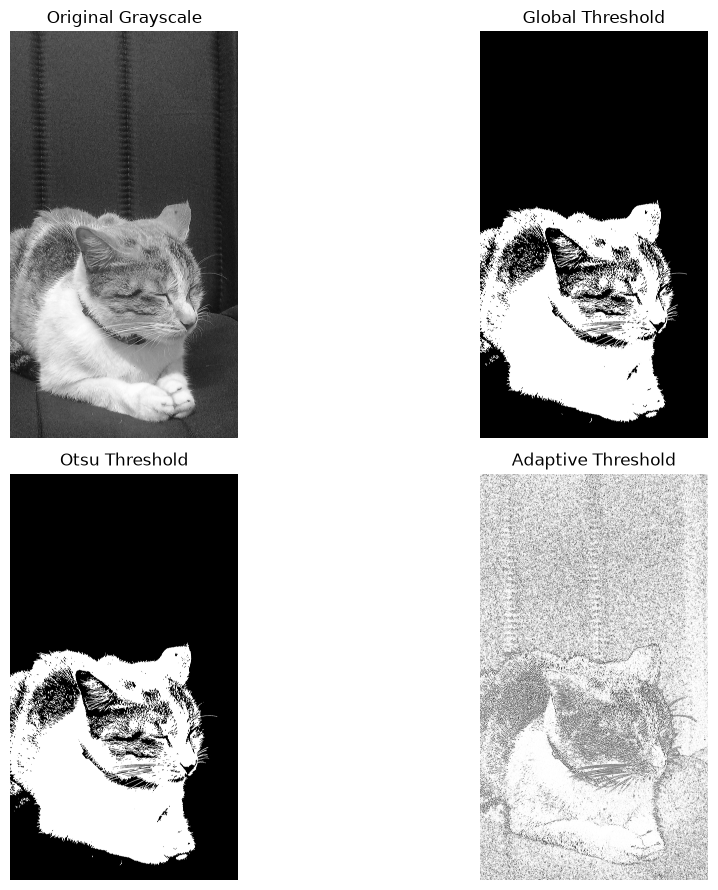

Thresholding results saved.


In [7]:

# Convert the original image to grayscale if not already available
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# 1. Global binary thresholding
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# 2. Otsu's automatic threshold selection
otsu_value, otsu_binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 3. Adaptive thresholding
adaptive_binary = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

print("Otsu threshold selected:", otsu_value)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].imshow(gray, cmap="gray")
axes[0, 0].set_title("Original Grayscale")

axes[0, 1].imshow(binary, cmap="gray")
axes[0, 1].set_title("Global Threshold")

axes[1, 0].imshow(otsu_binary, cmap="gray")
axes[1, 0].set_title("Otsu Threshold")

axes[1, 1].imshow(adaptive_binary, cmap="gray")
axes[1, 1].set_title("Adaptive Threshold")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(str(OUTPUT_DIR / "threshold_binary.png"), binary)
cv2.imwrite(str(OUTPUT_DIR / "threshold_otsu.png"), otsu_binary)
cv2.imwrite(str(OUTPUT_DIR / "threshold_adaptive.png"), adaptive_binary)

print("Thresholding results saved.")


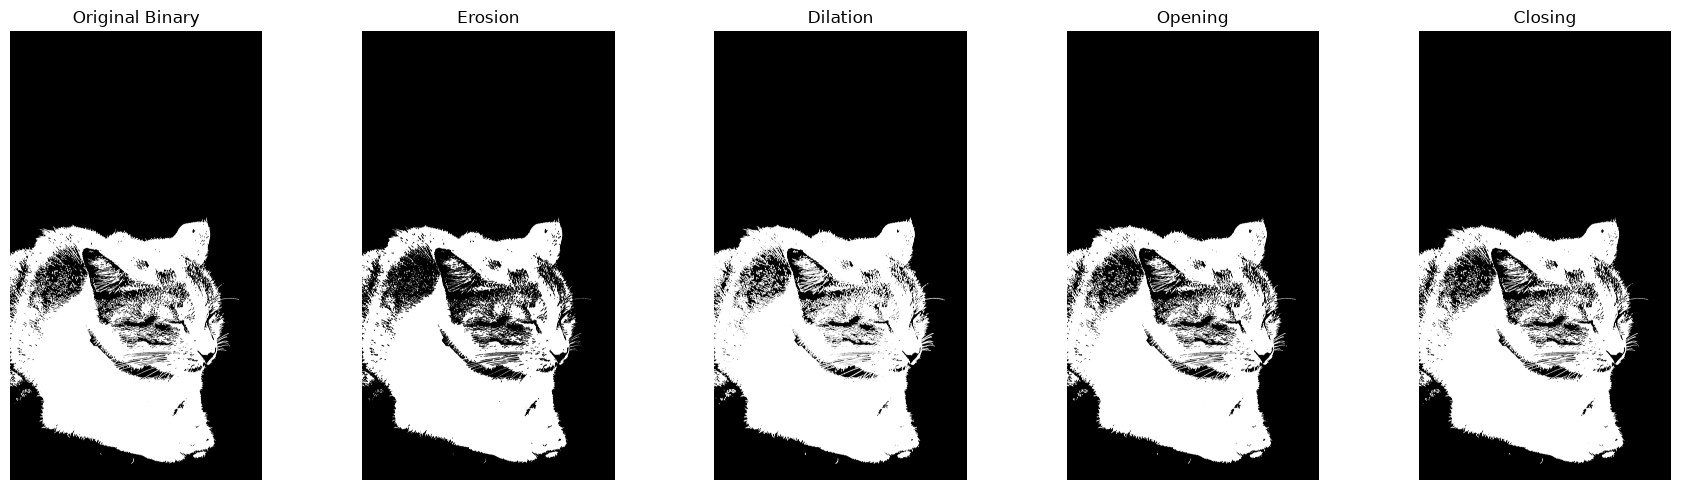

Morphological operation results saved.


In [8]:

# Use the Otsu binary image as the input
kernel = np.ones((5, 5), np.uint8)

# Erosion: shrinks foreground regions
erosion = cv2.erode(otsu_binary, kernel, iterations=1)

# Dilation: expands foreground regions
dilation = cv2.dilate(otsu_binary, kernel, iterations=1)

# Opening: erosion followed by dilation
opening = cv2.morphologyEx(
    otsu_binary, cv2.MORPH_OPEN, kernel
)

# Closing: dilation followed by erosion
closing = cv2.morphologyEx(
    otsu_binary, cv2.MORPH_CLOSE, kernel
)

operations = [
    ("Original Binary", otsu_binary),
    ("Erosion", erosion),
    ("Dilation", dilation),
    ("Opening", opening),
    ("Closing", closing)
]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, (title, result) in zip(axes, operations):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

for name, result in [
    ("erosion", erosion),
    ("dilation", dilation),
    ("opening", opening),
    ("closing", closing)
]:
    cv2.imwrite(str(OUTPUT_DIR / f"{name}.png"), result)

print("Morphological operation results saved.")


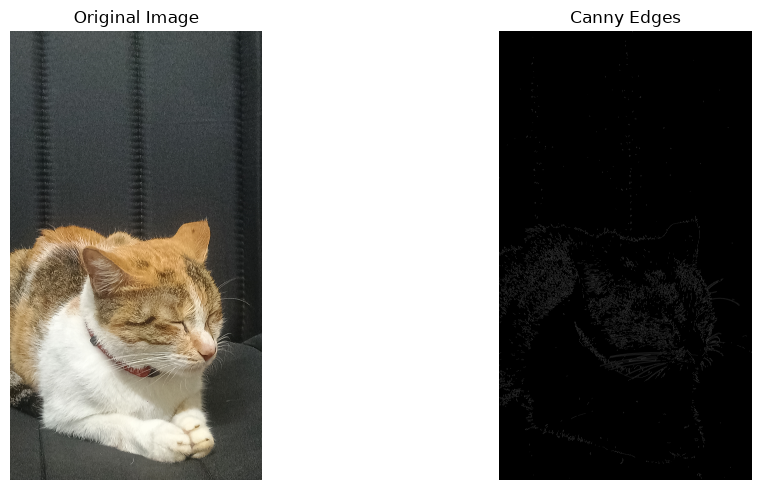

Canny edge image saved.


In [9]:

# Canny edge detection
edges = cv2.Canny(gray, 100, 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Canny Edges")
axes[1].axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(str(OUTPUT_DIR / "canny_edges.png"), edges)

print("Canny edge image saved.")


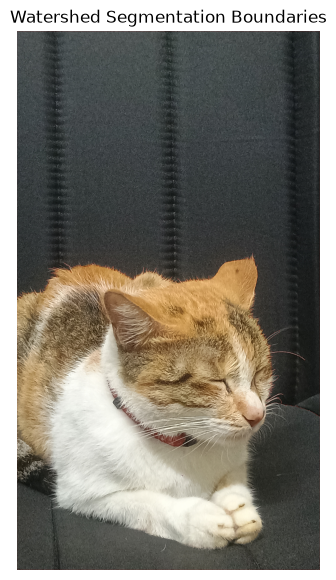

Watershed result saved.
Connected foreground components: 1


In [10]:

# Watershed segmentation
# Smooth the image to reduce small variations
blurred = cv2.GaussianBlur(image_bgr, (5, 5), 0)

# Create a binary foreground/background estimate
gray_blurred = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)
_, binary_ws = cv2.threshold(
    gray_blurred, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise and identify sure foreground
kernel_ws = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    binary_ws, cv2.MORPH_OPEN, kernel_ws, iterations=2
)

sure_bg = cv2.dilate(opening_ws, kernel_ws, iterations=3)

dist_transform = cv2.distanceTransform(
    opening_ws, cv2.DIST_L2, 5
)

_, sure_fg = cv2.threshold(
    dist_transform,
    0.4 * dist_transform.max(),
    255,
    cv2.THRESH_BINARY
)

sure_fg = sure_fg.astype(np.uint8)

# Unknown pixels will be assigned during watershed
unknown = cv2.subtract(sure_bg, sure_fg)

# Generate marker labels
num_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
markers = cv2.watershed(blurred.copy(), markers)

# Mark watershed boundaries in red
watershed_result = image_bgr.copy()
watershed_result[markers == -1] = [0, 0, 255]

watershed_rgb = cv2.cvtColor(
    watershed_result, cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 7))
plt.imshow(watershed_rgb)
plt.title("Watershed Segmentation Boundaries")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "watershed_boundaries.png"),
    watershed_result
)

print("Watershed result saved.")
print("Connected foreground components:", num_labels - 1)
